In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-pr-curves

**Figure 2: ROC curves of nine membership inference attacks against a CIFAR-10 model.** Both axes are log scale; the legend gives each attack's balanced accuracy, and the dashed diagonal marks a random-guess attack. Accuracy says little about low-FPR performance: Yeom et al. (59.5% accuracy) fails completely at low FPRs while Long et al. (53.5%) does better there, and ours reaches an 8.4% TPR at 0.1% FPR, 3.8× the best prior attack (Long et al., 2.2%).

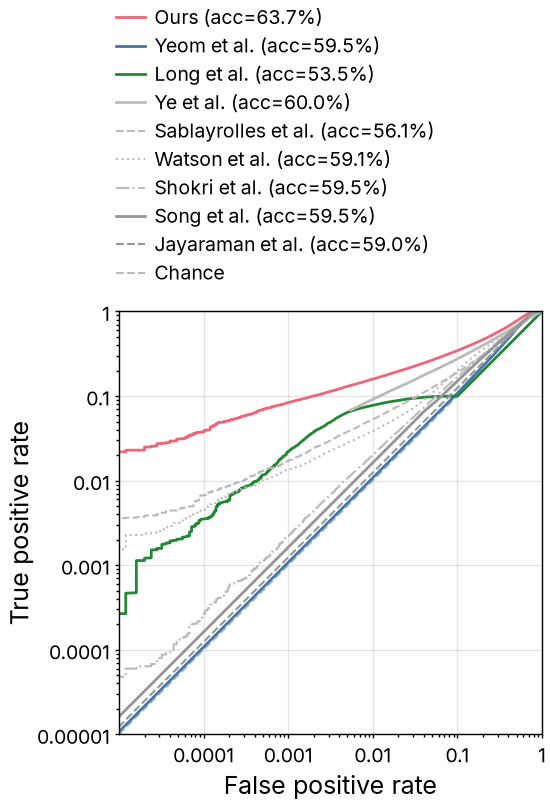

In [2]:
with open("../data/roc-pr-curves.json") as f:
    data = json.load(f)

fig, ax = plt.subplots(figsize=(2.75, 2.75))
grey = colors["neutral"]
styles = {
    "Ours": dict(color=colors["ours"], linestyle="-"),
    "Yeom et al.": dict(color=colors["series-1"], linestyle="-"),
    "Long et al.": dict(color=colors["series-3"], linestyle="-"),
    "Ye et al.": dict(color=grey, linestyle="-"),
    "Sablayrolles et al.": dict(color=grey, linestyle="--", linewidth=paper.dashed_width),
    "Watson et al.": dict(color=grey, linestyle=":", linewidth=paper.dashed_width),
    "Shokri et al.": dict(color=grey, linestyle="-.", linewidth=paper.dashed_width),
    "Song et al.": dict(color=darken(grey), linestyle="-"),
    "Jayaraman et al.": dict(color=darken(grey), linestyle="--", linewidth=paper.dashed_width),
}
curves = {c["method"]: c for c in data["curves"]}
for method, style in styles.items():
    curve = curves[method]
    ax.plot(curve["fpr"], curve["tpr"], label=f"{method} (acc={curve['attack_accuracy_percent']}%)", **style)
ax.plot(data["chance_line"]["fpr"], data["chance_line"]["tpr"], linestyle="--", linewidth=paper.dashed_width,
        color=grey, zorder=1, label="Chance")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-5, 1)
ax.set_ylim(1e-5, 1)
ticks = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
labels = ["0.00001", "0.0001", "0.001", "0.01", "0.1", "1"]
ax.set_xticks(ticks[1:], labels=labels[1:])
ax.set_yticks(ticks, labels=labels)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=1, frameon=False, borderaxespad=0)
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/roc-pr-curves.pdf")
fig.savefig("../outputs/roc-pr-curves.png")
plt.show()